# The multilayer perceptron
*Reading the Doors of Durin.*

Some problems resist code. Nobody can write the rule that tells one
scrawled letter from another, or a voice from noise; every attempt is a
thousand special cases and still wrong. The way round is to write a
function with parameters instead of a rule, collect examples of right answers,
and turn the parameters until the function gives them. The function then
answers new cases on its own.

The *multilayer perceptron* is the simplest such function that works at
scale: small identical parts, each with a few parameters, arranged in layers.
Every network in use today is built from it, from one that reads
handwriting to one that writes text. Below it is built up one part at a
time, each part tried on data until the data breaks it and the next part
is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import count, islice

MADDER, PRUSSIAN, VERDIGRIS = '#a4402c', '#1c4e73', '#2b6f68'
OCHRE, CONSTRUCT = '#b58a1e', '#c3c9cf'

## The doors

![The Doors of Durin](doors.png)

The west door of Moria is a smooth wall of rock with nothing to see on
it. Narvi the dwarf made it, and Celebrimbor the elf drew its signs in
*ithildin*, a silver alloy that stays invisible until starlight or
moonlight falls on it. Then a design appears: two trees, an arch, a crown
of seven stars, and round the arch a line of writing in Elvish letters.

## I. The perceptron

A perceptron takes a few numbers in. Each input is multiplied by its own
weight, and the products are added together with a bias. The sum is the
output.

![A linear perceptron](linear_perceptron.svg)

$$y = w \cdot x + b$$

The inputs are the vector $x$, the weights are the vector $w$, and $b$ is
the bias. The weights and the bias are the parameters of the perceptron.
Since the output is a weighted sum of the inputs, this is a *linear
perceptron*.

In code, $x$ is a matrix with one row per case, so that many cases go
through at once.


In [2]:
def linear_perceptron(x, w, b):
    return x @ w + b

x = np.array([[1.0, 2.0]])          # one case with two inputs
w, b = np.array([0.5, -1.0]), 0.2   # parameters, picked for the example
linear_perceptron(x, w, b)          # predict

array([-1.3])

### Problem I: how bright are the lines

Forty nights of the apprentice's readings, two numbers in and one out:

<table style="font-size: 1em">
<tr><th></th><th>symbol</th><th>reading</th><th>range</th></tr>
<tr><td>input</td><td><i>x</i><sub>1</sub></td>
    <td>time, the hour after sunset divided by 12</td><td>0 to 1</td></tr>
<tr><td>input</td><td><i>x</i><sub>2</sub></td>
    <td>haze over the mountains</td><td>0 to 1</td></tr>
<tr><td>output</td><td><i>t</i></td>
    <td>glow of the lines</td><td>0 to 1</td></tr>
</table>


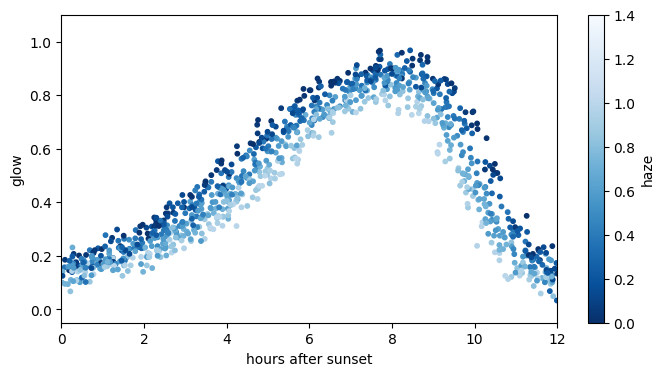

In [3]:
dataset = np.loadtxt('data/ithildin.csv', delimiter=',', skiprows=1)
night, hours, haze, glow = dataset.T
time = hours / 12
inputs = np.column_stack([time, haze])   # one row per reading

def draw_glow(rows=slice(None)):
    plt.figure(figsize=(8, 4))
    plt.scatter(hours[rows], glow[rows], c=haze[rows], cmap='Blues_r',
                vmin=0, vmax=1.4, s=10, label='readings')
    plt.colorbar(label='haze')
    plt.xlabel('hours after sunset'); plt.ylabel('glow')
    plt.xlim(0, 12); plt.ylim(-0.05, 1.1)

draw_glow()

### Training the linear perceptron

Each dot in the figure is one reading, coloured by its haze. Start with
the first five hours, where the glow rises. At a fixed haze the linear
perceptron is a straight line in time, and the figure below draws it for
a clear night and a hazy one.

#### The cost

For any choice of parameters, the perceptron predicts a glow $y_i$ for
every reading $i$. The difference between the predicted glow and the
recorded glow $t_i$ is called the residual of that reading:

$$r_i = y_i - t_i = w \cdot x_i + b - t_i$$

The cost is half the mean of the squared residuals over the $n$
readings:

$$C(w, b) = \frac{1}{2n}\sum_{i=1}^{n} r_i^2$$

#### Learning is minimization

Training means choosing $w$ and $b$ so that the cost is as small as
possible. That is the minimization problem of the previous lecture,

$$w^\star, b^\star = \underset{w,\,b}{\arg\min}\; C(w, b)$$

Training and prediction swap what varies and what stays fixed:

<table style="font-size: 1em">
<tr><th></th><th>function</th><th>input</th><th>constants</th><th>result</th></tr>
<tr><td>training</td><td>cost <i>C</i>(<i>w</i>, <i>b</i>)</td>
    <td>parameters <i>w</i>, <i>b</i></td>
    <td>readings <i>x</i><sub><i>i</i></sub>, <i>t</i><sub><i>i</i></sub></td>
    <td>parameters <i>w</i><sup>⋆</sup>, <i>b</i><sup>⋆</sup></td></tr>
<tr><td>prediction</td><td>perceptron <i>y</i> = <i>w</i> · <i>x</i> + <i>b</i></td>
    <td>case <i>x</i></td>
    <td>parameters <i>w</i>, <i>b</i></td>
    <td>glow <i>y</i></td></tr>
</table>

Each step in the code below is marked as one or the other.

#### The gradient

Gradient descent solves the minimization, and needs the slope of the
cost with respect to each parameter. The cost is a chain of two
functions: it depends on the predictions $y_i$, and each prediction
depends on the parameters. Each has a simple slope:

$$\frac{\partial C}{\partial y_i} = \frac{r_i}{n}, \qquad
\frac{\partial y_i}{\partial w_j} = x_{ij}, \qquad
\frac{\partial y_i}{\partial b} = 1$$

The chain rule multiplies the two slopes, and the readings add up:

$$\frac{\partial C}{\partial w_j}
= \sum_{i=1}^{n} \frac{\partial C}{\partial y_i}\,\frac{\partial y_i}{\partial w_j}
= \frac1n\sum_{i=1}^{n} r_i\,x_{ij}, \qquad
\frac{\partial C}{\partial b}
= \sum_{i=1}^{n} \frac{\partial C}{\partial y_i}\,\frac{\partial y_i}{\partial b}
= \frac1n\sum_{i=1}^{n} r_i$$

#### Gradient descent

Each step moves the parameters a little against the slope, with a step
length $\alpha$, as in the previous lecture. Here $k$ counts the steps:

$$w_{k+1} = w_k - \alpha\,\frac{\partial C}{\partial w}(w_k, b_k), \qquad
b_{k+1} = b_k - \alpha\,\frac{\partial C}{\partial b}(w_k, b_k)$$

After two thousand steps with $\alpha = 0.5$ the line follows the
readings: more time gives more glow, and more haze gives less.


(447, 2) (447,) n readings by 2 inputs, and n right answers
[ 1.07335412 -0.13565815] 0.15246386481514307 parameters


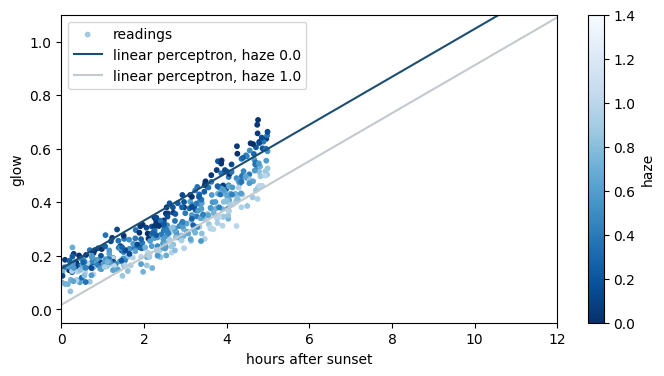

In [4]:
def cost(guess, truth):
    return 0.5 * np.mean((guess - truth)**2)

early = hours < 5
x1, t1 = inputs[early], glow[early]
print(x1.shape, t1.shape, 'n readings by 2 inputs, and n right answers')

w, b = np.zeros(2), 0.0
for _ in range(2000):                       # train
    r = linear_perceptron(x1, w, b) - t1    # all n residuals in one go, numpy row by row
    dw, db = x1.T @ r / len(r), r.mean()    # the slopes, summed over the readings
    w, b = w - 0.5 * dw, b - 0.5 * db       # gradient descent step, alpha = 0.5
print(w, b, 'parameters')

def draw_line(guess, haze, color, label):
    '''Predict along one night of a fixed haze.'''
    span = np.linspace(0, 12, 100)
    at = np.column_stack([span / 12, np.full(100, haze)])
    plt.plot(span, guess(at), color=color, label=f'{label}, haze {haze}')

draw_glow(early)
draw_line(lambda x: linear_perceptron(x, w, b), 0.0, PRUSSIAN, 'linear perceptron')
draw_line(lambda x: linear_perceptron(x, w, b), 1.0, CONSTRUCT, 'linear perceptron')
plt.legend();

### Where it fails

The same linear perceptron, with the same parameters, now predicts the
glow up to eight hours after sunset. It predicts a glow above 1. The
recorded glow never goes above 1, because the lines cannot shine brighter
than full silver. A straight line keeps climbing whatever its parameters,
so training on more readings would not help.


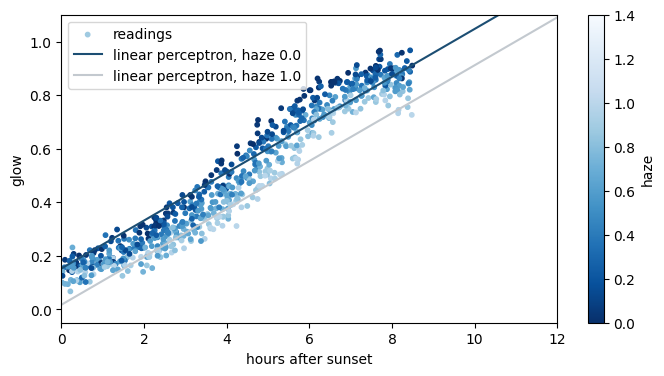

In [5]:
late = hours < 8.5
x2, t2 = inputs[late], glow[late]

draw_glow(late)
# predict past the hours it was trained on
draw_line(lambda x: linear_perceptron(x, w, b), 0.0, PRUSSIAN, 'linear perceptron')
draw_line(lambda x: linear_perceptron(x, w, b), 1.0, CONSTRUCT, 'linear perceptron')
plt.legend();

### Adding the activation function

Pass the sum through a fixed function $\sigma$ before it leaves the
perceptron:

![A perceptron](perceptron.svg)

$$z = w \cdot x + b, \qquad y = \sigma(z), \qquad
\sigma(z) = \frac{1}{1 + e^{-z}}$$

The function $\sigma$ is called the activation function. It is chosen
once and is not changed by training. The usual first choice is the
sigmoid above, drawn below. For large negative $z$ it is close to 0, for
large positive $z$ it is close to 1, and at $z = 0$ it is exactly
$\tfrac12$. In between it rises smoothly. Whatever the sum $z$ comes to,
the prediction lies between 0 and 1. The dashed line is the slope of the
sigmoid, which the gradient below needs. It is largest at $z = 0$, where
it is $\tfrac14$, and close to 0 at both ends.


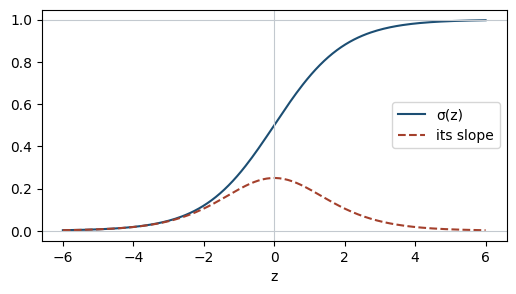

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def perceptron(x, w, b):
    return sigmoid(linear_perceptron(x, w, b))

zs = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3))
plt.plot(zs, sigmoid(zs), color=PRUSSIAN, label='σ(z)')
plt.plot(zs, sigmoid(zs) * (1 - sigmoid(zs)), '--', color=MADDER, label='its slope')
plt.axhline(0, color=CONSTRUCT, lw=0.8); plt.axhline(1, color=CONSTRUCT, lw=0.8)
plt.axvline(0, color=CONSTRUCT, lw=0.8)
plt.xlabel('z'); plt.legend();

As before, $y_i$ is the predicted glow and $t_i$ is the recorded glow.
The prediction now stays between 0 and 1, as the glow does. The cost is
the same function of the predictions, so its slope is unchanged:

$$\frac{\partial C}{\partial y_i} = \frac{r_i}{n}$$

What is new is the prediction as a function of the parameters, the
sigmoid of the sum:

$$y_i = \sigma(z_i), \qquad z_i = w \cdot x_i + b$$

Its slope is the slope of the sigmoid times the slope of the sum. The
slope of the sigmoid is the sigmoid times one minus itself:

$$\frac{d\sigma}{dz} = \frac{e^{-z}}{(1 + e^{-z})^2}
= \sigma(z)\bigl(1 - \sigma(z)\bigr)$$

$$\frac{\partial y_i}{\partial w_j} = y_i\,(1 - y_i)\,x_{ij}, \qquad
\frac{\partial y_i}{\partial b} = y_i\,(1 - y_i)$$

Multiply the two slopes and add up the readings, as before:

$$\frac{\partial C}{\partial w_j} = \frac1n\sum_{i=1}^{n} r_i\; y_i\,(1 - y_i)\; x_{ij}, \qquad
\frac{\partial C}{\partial b} = \frac1n\sum_{i=1}^{n} r_i\; y_i\,(1 - y_i)$$

Compared with the linear perceptron, the only new factor is
$y_i\,(1 - y_i)$, the slope of the sigmoid at each reading. The code
computes $r_i\,y_i\,(1 - y_i) / n$ once per reading, as `factor`, and
sums over the readings with a matrix product.

Trained on the readings up to eight hours, the perceptron levels off
where the line kept climbing.

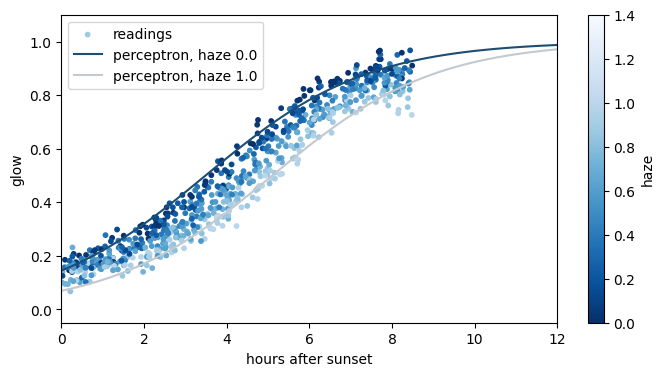

In [7]:
def train_perceptron(x, truth, steps=5000, alpha=3.0):
    w, b = np.zeros(2), 0.0
    for _ in range(steps):                  # train
        y = perceptron(x, w, b)
        factor = (y - truth) * y * (1 - y) / len(truth)   # r_i y_i (1 - y_i) / n, one per reading
        w, b = w - alpha * x.T @ factor, b - alpha * factor.sum()   # gradient descent step
    return w, b

w, b = train_perceptron(x2, t2)
draw_glow(late)
draw_line(lambda x: perceptron(x, w, b), 0.0, PRUSSIAN, 'perceptron')
draw_line(lambda x: perceptron(x, w, b), 1.0, CONSTRUCT, 'perceptron')
plt.legend();

## II. Multiple layers

A function that bends twice is made from two perceptrons that bend once
each. Put two perceptrons side by side, reading the same inputs, and feed
their outputs to one more perceptron that weighs them together. The two
side by side are a *hidden layer*: their outputs are never read
directly, only through the perceptron on top, the *output layer*.

![A hidden layer of two perceptrons, and the output layer](network.svg)

In section I the subscript on $w_j$ picked out one weight. From here on
the subscript is the layer. Layer $\ell$ has a weight matrix $W_\ell$,
a bias $b_\ell$ and an output $y_\ell$. Each has one column or entry per
perceptron, so that all the perceptrons of a layer are computed at
once. An entry gets its own indices after a comma:
$W_{\ell,jk}$ is the weight from input $j$ to perceptron $k$ of layer $\ell$,
and $y_{\ell,k}$ is the output of perceptron $k$. Each layer reads the output
of the one before it:

$$y_1 = \sigma(x\,W_1 + b_1), \qquad y_2 = y_1 W_2 + b_2$$

$W_1$ has two columns, one per hidden perceptron. The output layer is the
linear perceptron of section I reading $y_1$ instead of $x$, so $W_2$
has a single column and $y_2$ is the prediction. It has no $\sigma$ when
the answer is a number rather than a yes or no. A third layer would read
$y_2$ the same way. The code uses the same names: `W1, b1, W2, b2` for
the parameters and `y1, y2` for the outputs.


### The gradient

The cost is the same as for the single perceptron, with the prediction
now $y_2$, so its slope is again $\partial C / \partial y_{2,i} = r_i / n$.
Here $i$ numbers the readings, $j$ the inputs and $k$ the hidden perceptrons,
and the prediction is

$$y_{2,i} = \sum_k y_{1,ik}\, W_{2,k} + b_2, \qquad
y_{1,ik} = \sigma\Bigl(\sum_j x_{ij}\, W_{1,jk} + b_{1,k}\Bigr)$$

The output layer is the linear perceptron of section I reading $y_1$,
so its slopes are the ones found there, with $y_1$ in place of $x$:

$$\frac{\partial C}{\partial W_{2,k}} = \frac1n\sum_{i=1}^{n} r_i\, y_{1,ik}, \qquad
\frac{\partial C}{\partial b_2} = \frac1n\sum_{i=1}^{n} r_i$$

A hidden weight $W_{1,jk}$ changes the prediction only through perceptron $k$,
whose output is multiplied by $W_{2,k}$. That perceptron is the sigmoid
perceptron of section I, so its slope is already known:

$$\frac{\partial y_{2,i}}{\partial W_{1,jk}}
= W_{2,k}\,\frac{\partial y_{1,ik}}{\partial W_{1,jk}}
= W_{2,k}\; y_{1,ik}(1 - y_{1,ik})\; x_{ij}$$

For the bias $b_{1,k}$ the last factor $x_{ij}$ is 1. Multiply by
$\partial C / \partial y_{2,i}$ and add up the readings:

$$\frac{\partial C}{\partial W_{1,jk}}
= \frac1n\sum_{i=1}^{n} r_i\; W_{2,k}\; y_{1,ik}(1 - y_{1,ik})\; x_{ij}, \qquad
\frac{\partial C}{\partial b_{1,k}}
= \frac1n\sum_{i=1}^{n} r_i\; W_{2,k}\; y_{1,ik}(1 - y_{1,ik})$$

Each layer between a weight and the prediction multiplies in two more
factors: the weight its output is multiplied by, and the slope of its
sigmoid. In the code the sums over $i$ are matrix products, and the
factors shared by all the inputs are computed once per reading and
perceptron, as `through`. A difference quotient on one weight checks the
result against the apprentice's readings.


In [8]:
def forward(params, x):
    W1, b1, W2, b2 = params
    y1 = sigmoid(x @ W1 + b1)
    return y1, y1 @ W2 + b2

def gradient(params, x, y1, r):
    '''r holds r_i / n, one per reading.'''
    W1, b1, W2, b2 = params
    through = np.outer(r, W2) * y1 * (1 - y1)   # r_i / n  W_2k  y_1ik (1 - y_1ik)
    return [x.T @ through, through.sum(0), y1.T @ r, r.sum()]

def glow_grad(params):
    y1, y2 = forward(params, inputs)
    return gradient(params, inputs, y1, (y2 - glow) / len(glow))

def random_weights(inputs_in: int, hidden: int, rng):
    return [rng.normal(0, 1, (inputs_in, hidden)), np.zeros(hidden),
            rng.normal(0, 1, hidden), np.float64(0)]

params = random_weights(2, 2, np.random.default_rng(0))
bump = np.zeros((2, 2)); bump[0, 0] = 1e-6
before = cost(forward(params, inputs)[1], glow)
after_bump = cost(forward([params[0] + bump] + params[1:], inputs)[1], glow)
print((after_bump - before) / 1e-6, glow_grad(params)[0][0, 0])

0.04264379735441359 0.04264379734288958


### Problem I, the whole night

Over the whole night the glow rises and
then falls as the moon sets. A sigmoid only rises, or only falls, and one
perceptron has one sigmoid: trained on the whole dataset it settles for a
slope through the middle.

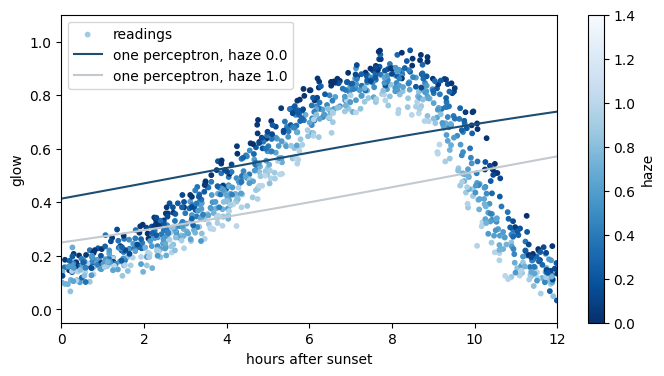

In [9]:
w, b = train_perceptron(inputs, glow)       # train on the whole night
draw_glow()
draw_line(lambda x: perceptron(x, w, b), 0.0, PRUSSIAN, 'one perceptron')
draw_line(lambda x: perceptron(x, w, b), 1.0, CONSTRUCT, 'one perceptron')
plt.legend();

### Training the two layers

Gradient descent on all four arrays at once, from random parameters, with
a fixed step length. The stepper is written as a generator that yields
where it stands, and `after` runs it a number of steps. The trained curve
follows the readings on clear nights and on hazy ones.

In [10]:
def gradient_descent(params, grad, alpha):
    while True:
        yield params
        params = [p - alpha * g for p, g in zip(params, grad(params))]

def after(steps, path):
    return next(islice(path, steps, None))

0.0010727673555737689 cost trained


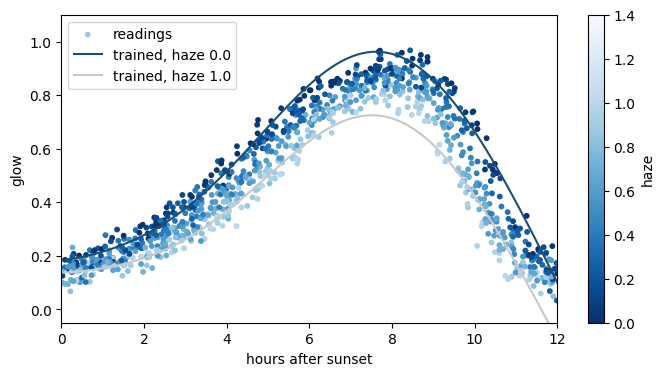

In [11]:
two_hidden = after(30000, gradient_descent(random_weights(2, 2, np.random.default_rng(0)),
                                         glow_grad, alpha=0.3))   # train
print(cost(forward(two_hidden, inputs)[1], glow), 'cost trained')   # predict on the dataset, and score

draw_glow()
draw_line(lambda x: forward(two_hidden, x)[1], 0.0, PRUSSIAN, 'trained')
draw_line(lambda x: forward(two_hidden, x)[1], 1.0, CONSTRUCT, 'trained')
plt.legend();

## III. The decision boundary

With two inputs and a yes or no for an output, the set of inputs where the
network changes its answer is a curve across the map, the *decision
boundary*. Each hidden perceptron contributes one straight line to it, and the
output layer decides which side of which lines counts as yes.

![The door network: a spot in, silver or stone out](door.svg)

The data: on the night at the doors, clouds crossed the moon and lit the
wall a patch at a time. Wherever a patch fell, the hobbits noted silver or
stone at each spot. Is a given spot on the door silver?

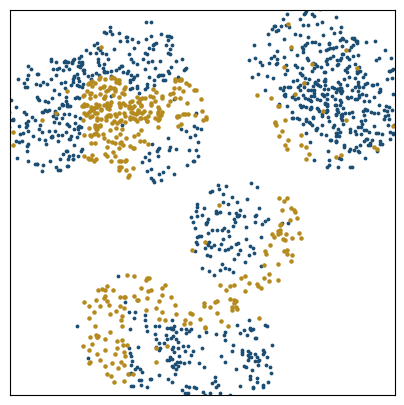

In [12]:
door = np.loadtxt('data/door.csv', delimiter=',', skiprows=1)
points, silver = door[:, :2], door[:, 2]

side = np.linspace(-1, 1, 200)
gx, gy = np.meshgrid(side, side)
frame = np.column_stack([gx.ravel(), gy.ravel()])

def draw_door(output=None, lines=None):
    if output is not None:
        plt.pcolormesh(gx, gy, output.reshape(gx.shape), cmap='gray', vmin=0, vmax=1)
    if lines is not None:
        W, b = lines
        for k in range(W.shape[1]):
            edge = (frame @ W[:, k] + b[k]).reshape(gx.shape)
            plt.contour(gx, gy, edge, levels=[0], colors=MADDER, linewidths=0.8)
    stone = silver == 0
    plt.scatter(*points[stone].T, s=3, color=PRUSSIAN)
    plt.scatter(*points[~stone].T, s=5, color=OCHRE)
    plt.axis((-1, 1, -1, 1)); plt.gca().set_aspect('equal')
    plt.xticks([]); plt.yticks([])

plt.figure(figsize=(5, 5))
draw_door()

### Cross-entropy

Pass the output through the sigmoid as well, so that $p = \sigma(\cdot)$
lies between 0 and 1 and reads as the network's output for "silver". For
a yes or no the cost is *cross-entropy*: $-\log p$ where the truth is 1
and $-\log(1-p)$ where it is 0, so that a wrong answer given with $p$ near
0 or 1 costs a great deal.

$$C = -\tfrac1n \textstyle\sum_i \bigl(t_i \log p_i + (1 - t_i)\log(1 - p_i)\bigr)$$

Its slope through the output sigmoid collapses to $p - t$: the same residual
as before, so `gradient` is reused unchanged. The whole set of points goes
through as one matrix, a row per point, which is called a *batch*. The
stepper from here on is Adam, the one from the previous notebook, used as
it stands because it is quicker.

In [13]:
def classify(params, x):
    y1, z = forward(params, x)
    return y1, sigmoid(z)

def cross_entropy(p, truth):
    p = np.clip(p, 1e-12, 1 - 1e-12)  # a saturated sigmoid would give log 0
    return -np.mean(truth * np.log(p) + (1 - truth) * np.log(1 - p))

def door_grad(params):
    y1, p = classify(params, points)
    return gradient(params, points, y1, (p - silver) / len(points))

def adam(params, grad, alpha, b1=0.9, b2=0.999):
    m = [np.zeros_like(p) for p in params]
    s = [np.zeros_like(p) for p in params]
    for k in count(1):
        yield params
        g = grad(params)
        m = [b1 * mi + (1 - b1) * gi for mi, gi in zip(m, g)]
        s = [b2 * si + (1 - b2) * gi**2 for si, gi in zip(s, g)]
        params = [p - alpha * (mi / (1 - b1**k)) / (np.sqrt(si / (1 - b2**k)) + 1e-8)
                  for p, mi, si in zip(params, m, s)]

def fit_door(hidden, steps=3000, alpha=0.03, seed=0):
    '''Train on every noted point at once.'''
    path = adam(random_weights(2, hidden, np.random.default_rng(seed)), door_grad, alpha)
    return after(steps, path)

def show_door(params):
    '''Predict at the noted points, to score, and over the whole frame, to draw.'''
    _, p = classify(params, points)
    _, output = classify(params, frame)
    draw_door(output, params[:2])
    plt.title(f'{params[0].shape[1]} perceptrons, {np.mean((p > 0.5) == silver):.0%} right')

### One perceptron

A single perceptron splits the door along the straight line
$x \cdot w + b = 0$, where its output crosses one half: silver on one side,
stone on the other. The best such line is drawn in red. It is wrong in
plain sight, and only a little better than calling every spot stone.

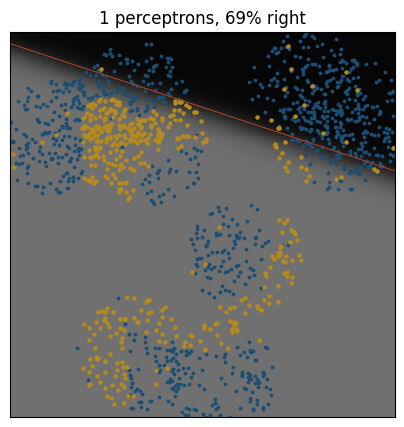

In [14]:
plt.figure(figsize=(5, 5))
show_door(fit_door(1))

### Two perceptrons

Two lines, weighed with opposite signs by the output layer,
make a band: the bump of the hidden layer, across a map. It lands on the
stem of the letter, with one line along each edge.

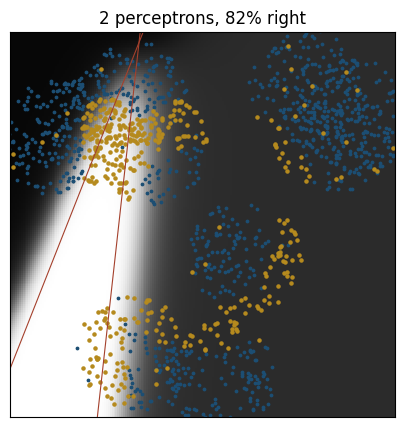

In [15]:
plt.figure(figsize=(5, 5))
show_door(fit_door(2))

### More perceptrons

Every hidden perceptron is one straight line, and the output layer
adds up which side of each a point lies on. A curve takes many lines. With
four and eight the bow is a few straight pieces; by sixteen it closes, and
at thirty-two the edge is smooth and the lines too many to read one by
one.

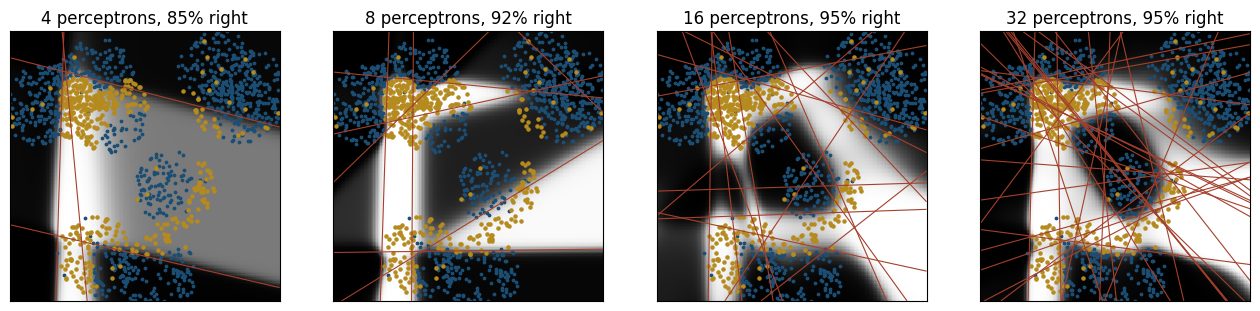

In [16]:
plt.figure(figsize=(16, 4))
for i, hidden in enumerate([4, 8, 16, 32]):
    plt.subplot(1, 4, i + 1)
    show_door(fit_door(hidden))

### Watching it train

Sixteen perceptrons from a random start, drawn after 0,
30, 100, 300, 1000 and 3000 steps. The lines begin anywhere, and move to
where the mistakes are.

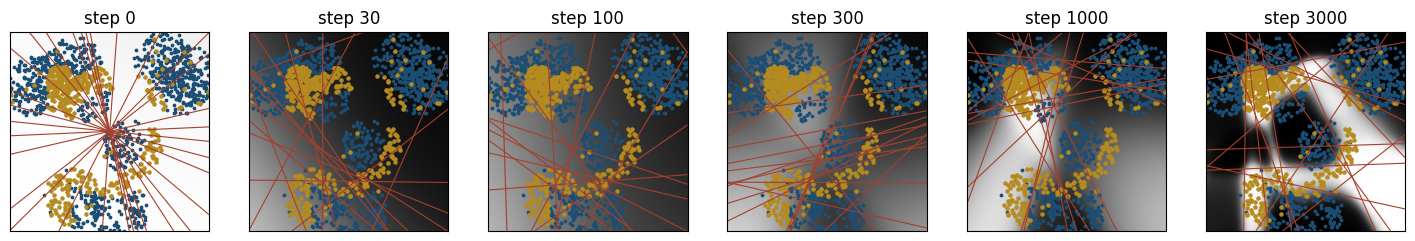

In [17]:
path = adam(random_weights(2, 16, np.random.default_rng(0)), door_grad, alpha=0.03)
snapshots = [0, 30, 100, 300, 1000, 3000]
plt.figure(figsize=(18, 3.3))
for step, params in zip(range(snapshots[-1] + 1), path):
    if step in snapshots:
        plt.subplot(1, 6, snapshots.index(step) + 1)
        show_door(params)
        plt.title(f'step {step}')

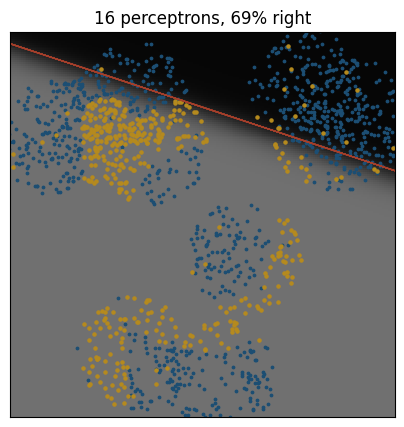

In [18]:
zeros = [np.zeros((2, 16)), np.zeros(16), np.zeros(16), np.float64(0)]
plt.figure(figsize=(5, 5))
show_door(after(3000, adam(zeros, door_grad, alpha=0.03)))

### Breaking it: too long a step

The same sixteen perceptrons, with plain
gradient descent at step lengths 1, 10 and 100. The first crawls, the
second descends, and the third throws the parameters past the bottom every
step, so the cost climbs instead of falling.

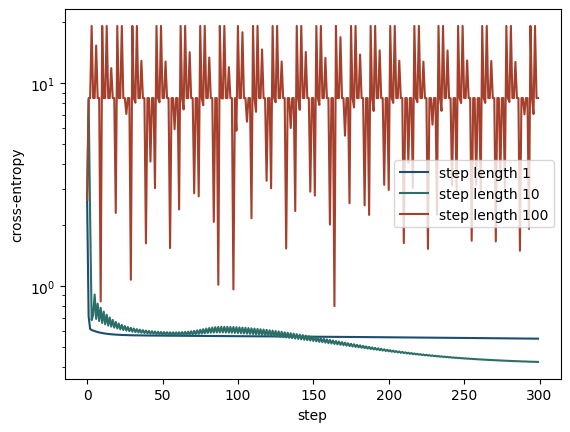

In [19]:
for alpha, color in [(1, PRUSSIAN), (10, VERDIGRIS), (100, MADDER)]:
    path = gradient_descent(random_weights(2, 16, np.random.default_rng(0)), door_grad, alpha)
    costs = [cross_entropy(classify(p, points)[1], silver) for p in islice(path, 300)]
    plt.plot(costs, color=color, label=f'step length {alpha}')
plt.yscale('log'); plt.xlabel('step'); plt.ylabel('cross-entropy'); plt.legend();

## IV. Reading letters

The inscription on the door is written in *Tengwar*, the alphabet
Tolkien made for his Elvish languages. In the story it was devised by
the elf Fëanor. Its letters are built from a stem and one or two bows,
and the shape of a letter follows how its sound is spoken, so letters
for related sounds look alike. In most writing modes the vowels are
small marks above the consonants, but the door is written in the mode
of Beleriand, where vowels are full letters.

The data holds twelve of the letters on the door. The task is to read a
letter from a picture of it. Each picture is 16 by 16 pixels, so a
picture is 256 numbers in, and the answer is one of the twelve letters.
One picture from the data:


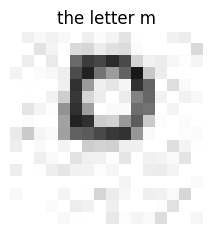

In [20]:
LETTERS = 12

letter_data = np.load('data/tengwar.npz')
names = [str(name) for name in letter_data['names']]

def pixels(images):
    return images.reshape(len(images), -1) / 255   # one row per picture, 0 to 1

def show_grid(images, titles, columns=12):
    rows = -(-len(images) // columns)
    plt.figure(figsize=(columns, 1.3 * rows))
    for i, (image, title) in enumerate(zip(images, titles)):
        side = int(np.sqrt(image.size))
        plt.subplot(rows, columns, i + 1)
        plt.imshow(image.reshape(side, side), cmap='gray_r', vmin=0, vmax=1)
        plt.title(title, fontsize=9); plt.axis('off')

picture, label = letter_data['moved_train_images'][0], letter_data['moved_train_labels'][0]
plt.figure(figsize=(2.5, 2.5))
plt.imshow(picture, cmap='gray_r', vmin=0, vmax=255)
plt.title(f'the letter {names[label]}'); plt.axis('off');

The twelve letters are drawn below, each labelled with the sound it
stands for: first drawn clean, then as they appear in the pictures,
moved and turned a little, as on the door.


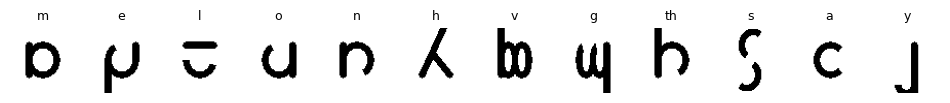

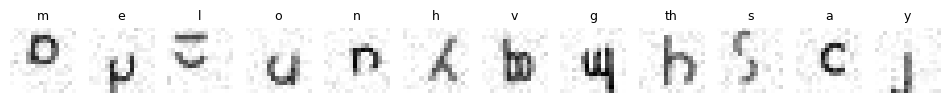

In [21]:
pictures, labels = pixels(letter_data['moved_train_images']), letter_data['moved_train_labels']

show_grid(letter_data['clean_images'], names[:LETTERS])
first = [np.flatnonzero(labels == k)[0] for k in range(LETTERS)]
show_grid(pictures[first], names[:LETTERS])

### Training and validation sets

The pictures come in two sets. The network trains on the *training
set*. The *validation set* is kept aside and never trained on, and is
used to measure how well the network reads pictures it has not seen.


In [22]:
train_x, train_t = pictures, labels
val_x, val_t = pixels(letter_data['moved_val_images']), letter_data['moved_val_labels']
print(len(train_x), 'training pictures,', len(val_x), 'validation pictures')

3600 training pictures, 1200 validation pictures


### One-hot encoding

The answer for a picture is one of twelve letters, numbered 0 to 11. The
network has twelve outputs, one per letter, so to compare the answer
with the outputs it is written as twelve numbers as well: a 1 at the
right letter and a 0 at every other. This is called *one-hot encoding*.
The truth for picture $i$ is then a vector $t_i$ with one entry $t_{ik}$
per letter $k$, and the truths for all the pictures form a matrix with
one row per picture, the same shape as the outputs.


In [23]:
def one_hot(truth):
    return np.eye(LETTERS)[truth]

three = train_t[::300][:3]   # three pictures of different letters
print(three, [names[k] for k in three])
print(one_hot(three))

[0 1 2] ['m', 'e', 'l']
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


### Softmax

The output layer has twelve perceptrons, and gives one score $z_k$ per
letter. The *softmax* turns the twelve scores into twelve positive
numbers that sum to one, so that they can be read as probabilities, one
per letter:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

The exponential makes every number positive and makes the largest score
stand out. The division makes the numbers sum to one. Adding the same
number to every score does not change the result, which the code uses to
keep the exponentials from overflowing.


In [24]:
def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

scores = np.array([[2.0, 0.5, -1.0]])
print(softmax(scores).round(3), softmax(scores).sum())
print(softmax(scores + 10).round(3), 'the same, shifted')

[[0.786 0.175 0.039]] 1.0
[[0.786 0.175 0.039]] the same, shifted


### Cross-entropy for several answers

The cost is minus the logarithm of the probability given to the right
letter, averaged over the pictures. With the one-hot truth, the sum over
the letters picks out that one probability, since every other $t_{ik}$
is 0:

$$C = -\frac1n \sum_{i=1}^{n} \sum_k t_{ik} \log p_{ik}$$

Its slope with respect to the scores is $(p - t) / n$: output minus
truth, as before. The derivation, and why softmax and cross-entropy
belong together, is not covered here.


In [25]:
def letter_cost(p, truth):
    return -np.sum(one_hot(truth) * np.log(p)) / len(p)

def residual(p, truth):
    '''The slope of cross-entropy at the scores.'''
    return (p - one_hot(truth)) / len(p)

### The network

The network is the two layers of section II with 256 inputs, 128 hidden
perceptrons and twelve output perceptrons, with softmax on the twelve
scores:

![The letter network: 256 pixels, 128 hidden perceptrons, 12 letters](letters.svg)

The gradient is that of section II with twelve outputs in place of one.
The residual is a matrix with one column per letter, and on the way to
the hidden layer the sum over the letters is one more matrix product,
$r\,W_2^{\mathsf T}$ in place of $r_i\, W_{2,k}$.


In [26]:
def read(params, x):
    W1, b1, W2, b2 = params
    return softmax(sigmoid(x @ W1 + b1) @ W2 + b2)

def read_grad(params, x, truth):
    W1, b1, W2, b2 = params
    y1 = sigmoid(x @ W1 + b1)
    r = residual(softmax(y1 @ W2 + b2), truth)
    through = (r @ W2.T) * y1 * (1 - y1)
    return [x.T @ through, through.sum(0), y1.T @ r, r.sum(0)]

def random_layer(inputs, outputs, rng):
    return [rng.normal(0, 1 / np.sqrt(inputs), (inputs, outputs)), np.zeros(outputs)]

def accuracy(params, x, truth):
    '''Predict every picture and count the right answers.'''
    return np.mean(read(params, x).argmax(axis=1) == truth)

### Batches

The gradient over the whole training set needs a prediction and a
gradient for every picture. Instead, each Adam step uses the gradient
over 64 pictures drawn at random, a *batch*. That gradient points
roughly the same way and costs much less to compute. This is called
*stochastic gradient descent*. An *epoch* is as many steps as it takes
to draw as many pictures as the training set holds.


In [27]:
BATCH = 64

def train(params, x, truth, epochs, rng, alpha=0.003):
    '''Train: each Adam step on a fresh batch of pictures. Yields after every epoch.'''
    def batch_grad(params):
        batch = rng.integers(0, len(x), BATCH)
        return read_grad(params, x[batch], truth[batch])
    path = adam(params, batch_grad, alpha)
    for epoch in range(epochs):
        yield after(len(x) // BATCH, path)

def costs(params, x, truth):
    '''The cost on the pictures trained on, and on the validation set.'''
    return letter_cost(read(params, x), truth), letter_cost(read(params, val_x), val_t)

def draw_costs(curves):
    training, validation = np.array(curves).T
    plt.plot(training, color=PRUSSIAN, label='training')
    plt.plot(validation, color=MADDER, label='validation')
    plt.xlabel('epoch'); plt.ylabel('cross-entropy'); plt.legend()

### Training

Sixty epochs from random parameters. The cost is recorded after every
epoch, on the training set and on the validation set. Both fall quickly
at first and flatten out after about thirty epochs. The validation cost
stays a little above the training cost, since the network has never
seen those pictures.


98.6% of the validation pictures right


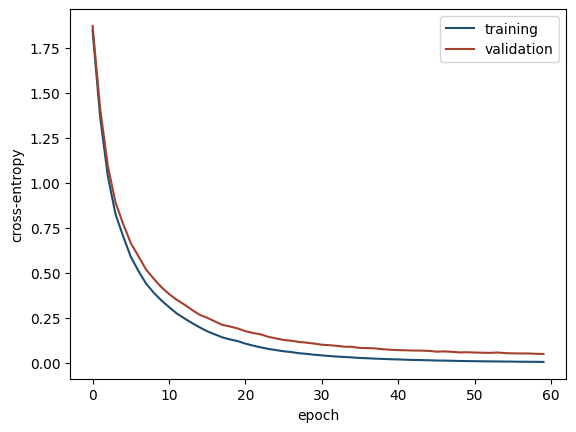

In [28]:
rng = np.random.default_rng(3)
path = list(train(random_layer(256, 128, rng) + random_layer(128, LETTERS, rng),
                  train_x, train_t, 60, rng))
network = path[-1]
draw_costs([costs(params, train_x, train_t) for params in path])
print(f'{accuracy(network, val_x, val_t):.1%} of the validation pictures right')

### Some predictions

One validation picture per letter, with the clean letter the network
read above it and the probability it gave that answer. All twelve are
right. On most the probability is close to 1, and on the less clear
ones it is lower.


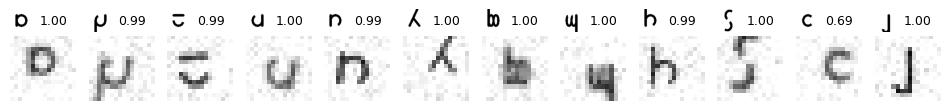

In [29]:
clean = letter_data['clean_images']   # 64 by 64, ink is True
COLUMNS = 12

def draw_letter(ax, image):
    ax.imshow(image, cmap='gray_r', vmin=0, vmax=1); ax.axis('off')

def draw_picture(rows, n, picture):
    '''Draw a picture as tile n of a grid, and return its axes.'''
    ax = plt.subplot(rows, COLUMNS, n + 1)
    draw_letter(ax, picture.reshape(16, 16))
    return ax

some = val_x[::100]   # one picture of each letter
outputs = read(network, some)   # predict
plt.figure(figsize=(12, 1.8))
for n, (picture, p) in enumerate(zip(some, outputs)):
    ax = draw_picture(1, n, picture)
    draw_letter(ax.inset_axes([0.0, 1.05, 0.35, 0.35]), clean[p.argmax()])
    ax.text(0.45, 1.22, f'{p.max():.2f}', transform=ax.transAxes, va='center', fontsize=9)

### What it misreads

The validation pictures the network gets wrong. Above each picture is
the clean letter it should have been read as, then "as", then the clean
letter the network read.


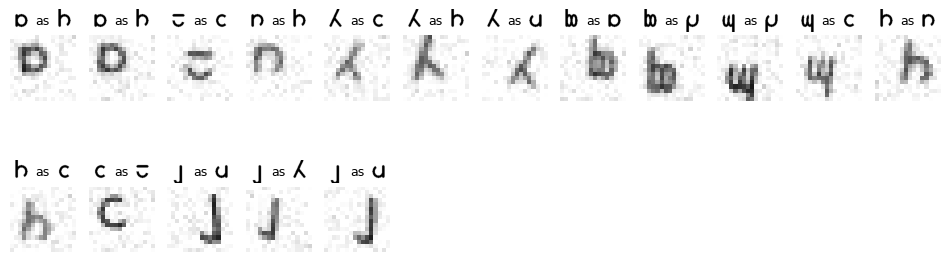

In [30]:
answers = read(network, val_x).argmax(axis=1)  # predict
wrong = np.flatnonzero(answers != val_t)[:24]
rows = -(-len(wrong) // COLUMNS)
plt.figure(figsize=(12, 1.8 * rows))
for n, i in enumerate(wrong):
    ax = draw_picture(rows, n, val_x[i])
    draw_letter(ax.inset_axes([0.0, 1.05, 0.35, 0.35]), clean[val_t[i]])
    draw_letter(ax.inset_axes([0.65, 1.05, 0.35, 0.35]), clean[answers[i]])
    ax.text(0.5, 1.22, 'as', transform=ax.transAxes, ha='center', va='center', fontsize=9)

### Overfitting

Train the same network on only twenty pictures per letter, for eighty
epochs, and record the cost on those pictures and on the validation set
after each epoch. The training cost keeps falling, because 34,000
parameters can fit 240 pictures exactly. The validation cost turns and
rises. Only pictures the network never trained on tell how well it
reads.


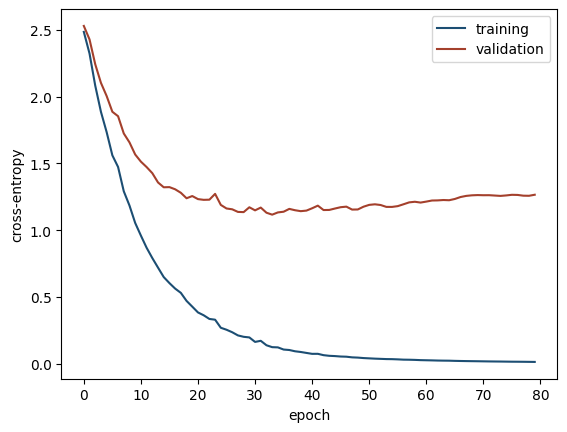

In [31]:
few = np.concatenate([np.flatnonzero(train_t == k)[:20] for k in range(LETTERS)])
few_x, few_t = train_x[few], train_t[few]
few_path = train(random_layer(256, 128, rng) + random_layer(128, LETTERS, rng),
                 few_x, few_t, 80, rng, alpha=0.01)
draw_costs([costs(params, few_x, few_t) for params in few_path])

### The word on the door

Six letters from the inscription on the door, read one at a time by the
network. Each is printed as the sound it stands for.


mellon


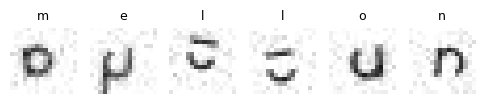

In [32]:
word_x = pixels(letter_data['word_images'])
answers = read(network, word_x).argmax(axis=1)  # predict
show_grid(word_x, [names[k] for k in answers], columns=6)
print(''.join(names[k] for k in answers))

### What it cannot do

A thirteenth letter, rómen, was not among the training pictures. The
network has twelve outputs and no way to answer "none of these", so it
picks one of the twelve, often with a high probability. A letter drawn
at twice the size does not fit the 16 by 16 pictures the weights were
trained on, and is misread in the same way.


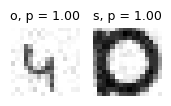

In [33]:
unseen = pixels(np.stack([letter_data['unseen_image'], letter_data['giant_image']]))
outputs = read(network, unseen)  # predict
show_grid(unseen, [f'{names[o.argmax()]}, p = {o.max():.2f}' for o in outputs], columns=3)